# Muse archive analysis

Explore how your recordings have changed across sessions and over time. The notebook reads the original Muse CSVs and builds session summaries in memory. It runs separately from the synthetic-data and EegML notebooks.

**Run All** to scan the archive and show gamma level, left-versus-right gamma, and the other four EEG bands. The last section shows how the two front channels changed within one recording.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ARCHIVE = Path.home() / "Documents" / "Yijing" / "Muse"
INSPECT_RECORDING = None  # None selects the most recent usable recording.
SENSOR_PAIR = "Front"  # Use "Rear" for TP9 and TP10 in the other-band plots.

STARTUP_SECONDS = 120
WINDOW_SECONDS = 30
MIN_SECONDS_PER_WINDOW = 24
MIN_WINDOWS_PER_SESSION = 3
MIN_SESSIONS_PER_MONTH = 3

BANDS = ("Delta", "Theta", "Alpha", "Beta", "Gamma")
PAIRS = {"Front": ("AF7", "AF8"), "Rear": ("TP9", "TP10")}
EEG_COLUMNS = [
    f"{band}_{sensor}" for band in BANDS for sensor in ("TP9", "AF7", "AF8", "TP10")
]
GYRO_COLUMNS = ["Gyro_X", "Gyro_Y", "Gyro_Z"]
OPTIONAL_COLUMNS = ["HeadBandOn", *GYRO_COLUMNS]

## How sessions are compared

- Recording dates come from the timestamps inside each file. The first two minutes are omitted because the Bluetooth capture code can use that period as its baseline.
- The analysis takes one median per second, then one median per 30-second window. A window needs at least 24 seconds with readings. Each recording has equal weight in the monthly summaries.
- **Front gamma** is the average of AF7 and AF8 in each paired reading. The **upper gamma** statistic is the 90th percentile of the window medians, so a brief spike carries less weight. **Right minus left** is AF8 minus AF7. Positive values indicate higher readings on the right.
- Plots and early-to-late comparisons separate the earlier Mellow CSV format and the later PPG CSV format. The formats are a proxy for capture settings. The recording code can change the scale or baseline, so compare trends within each format.
- Rows explicitly marked as headset off are omitted. For files with varying gyroscope readings, the summary also reports gamma and right-minus-left after omitting the highest-motion tenth of windows. Constant motion or contact fields provide little information, and low motion alone does not rule out muscle activity.

In [2]:
def summarize_recording(path):
    """Read one recording and return its session and window summaries."""
    header = pd.read_csv(path, nrows=0).columns
    missing = set(["TimeStamp", *EEG_COLUMNS]) - set(header)
    if missing:
        raise ValueError(f"Missing columns: {', '.join(sorted(missing))}")

    if "PPG_IR" in header:
        recording_format = "PPG format"
    elif "Mellow" in header:
        recording_format = "Mellow format"
    else:
        recording_format = "Other format"

    wanted = ["TimeStamp", *EEG_COLUMNS, *OPTIONAL_COLUMNS]
    data = pd.read_csv(path, usecols=[c for c in wanted if c in header], low_memory=False)
    times = pd.to_datetime(data["TimeStamp"], format="mixed", errors="coerce")
    values = (
        data.reindex(columns=[*EEG_COLUMNS, *OPTIONAL_COLUMNS])
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    timed_eeg = times.notna() & values[EEG_COLUMNS].notna().any(axis=1)
    start = times[timed_eeg].min()
    if pd.isna(start):
        raise ValueError("No timestamped EEG readings.")

    elapsed = (times - start).dt.total_seconds()
    headset_off = values["HeadBandOn"].eq(0).fillna(False)
    usable = timed_eeg & elapsed.ge(STARTUP_SECONDS) & ~headset_off
    values = values.loc[usable]
    seconds = elapsed.loc[usable].astype(int)

    signals = {}
    for band in BANDS:
        for pair, (left_sensor, right_sensor) in PAIRS.items():
            left = values[f"{band}_{left_sensor}"]
            right = values[f"{band}_{right_sensor}"]
            signals[f"{band}_{pair}"] = (left + right) / 2
            if band == "Gamma" and pair == "Front":
                paired = left.notna() & right.notna()
                signals["Gamma_AF7"] = left.where(paired)
                signals["Gamma_AF8"] = right.where(paired)
                signals["Gamma_right_minus_left"] = right - left

    signals["Gyro_speed"] = np.sqrt(values[GYRO_COLUMNS].pow(2).sum(axis=1, min_count=3))
    per_second = pd.DataFrame(signals).groupby(seconds).median()
    window_start = STARTUP_SECONDS + (per_second.index - STARTUP_SECONDS) // WINDOW_SECONDS * WINDOW_SECONDS
    grouped = per_second.groupby(window_start)
    windows = grouped.median().where(grouped.count() >= MIN_SECONDS_PER_WINDOW)
    windows.index.name = "Seconds from start"
    windows = windows.dropna(subset=["Gamma_Front"])
    if len(windows) < MIN_WINDOWS_PER_SESSION:
        raise ValueError(f"Only {len(windows)} usable front gamma windows.")

    summary = {
        "File": path.name,
        "Format": recording_format,
        "Started": start,
        "Duration_minutes": elapsed[timed_eeg].max() / 60,
        "Windows": len(windows),
        "Headset_off_rows": int((timed_eeg & headset_off).sum()),
        **windows.drop(columns="Gyro_speed").median().to_dict(),
        "Gamma_upper": windows["Gamma_Front"].quantile(0.9),
    }
    gyro = windows["Gyro_speed"].dropna()
    if len(gyro) >= 10 and gyro.quantile(0.9) > gyro.quantile(0.1):
        quieter = windows.loc[gyro.index[gyro <= gyro.quantile(0.9)]]
        summary["Gamma_lower_motion"] = quieter["Gamma_Front"].median()
        summary["Side_lower_motion"] = quieter["Gamma_right_minus_left"].median()
    return summary, windows

In [3]:
if not ARCHIVE.is_dir():
    raise FileNotFoundError(f"Set ARCHIVE to your Muse CSV folder. Current path: {ARCHIVE}")

files = sorted(path for path in ARCHIVE.iterdir() if path.suffix.lower() == ".csv" and path.is_file())
summaries, skipped = [], []
for i, path in enumerate(files, start=1):
    try:
        summary, _ = summarize_recording(path)
        summaries.append(summary)
    except (ValueError, OSError) as error:
        skipped.append({"File": path.name, "Reason": str(error)})
    if i % 50 == 0:
        print(f"Read {i} of {len(files)} recordings.")

if not summaries:
    raise ValueError(f"No usable recordings in {ARCHIVE}. First skipped files: {skipped[:3]}")

sessions = pd.DataFrame(summaries).sort_values("Started", ignore_index=True)
formats = list(sessions["Format"].unique())
print(f"Summarized {len(sessions)} of {len(files)} CSV files.")
display(sessions.groupby("Format", sort=False).agg(
    Sessions=("File", "size"),
    First=("Started", "min"),
    Last=("Started", "max"),
    Median_minutes=("Duration_minutes", "median"),
    Median_windows=("Windows", "median"),
).round({"Median_minutes": 1, "Median_windows": 1}))
if skipped:
    display(pd.DataFrame(skipped))

Read 50 of 358 recordings.
Read 100 of 358 recordings.
Read 150 of 358 recordings.
Read 200 of 358 recordings.
Read 250 of 358 recordings.
Read 300 of 358 recordings.
Read 350 of 358 recordings.
Summarized 358 of 358 CSV files.


,Sessions,First,Last,Median_minutes,Median_windows
Format,,,,,
Mellow format,282,2022-12-04 18:38:21.622,2026-05-04 18:04:37.604,40.6,76.0
PPG format,76,2026-05-07 17:40:34.712,2026-11-08 18:23:54.525,50.1,95.0


## Gamma level and left-to-right shift

Each faint dot is a session. A larger dot marks a monthly median where at least three sessions are available. Read the signed AF8 − AF7 panel together with the separate AF7 and AF8 lines to see which side drove the change.

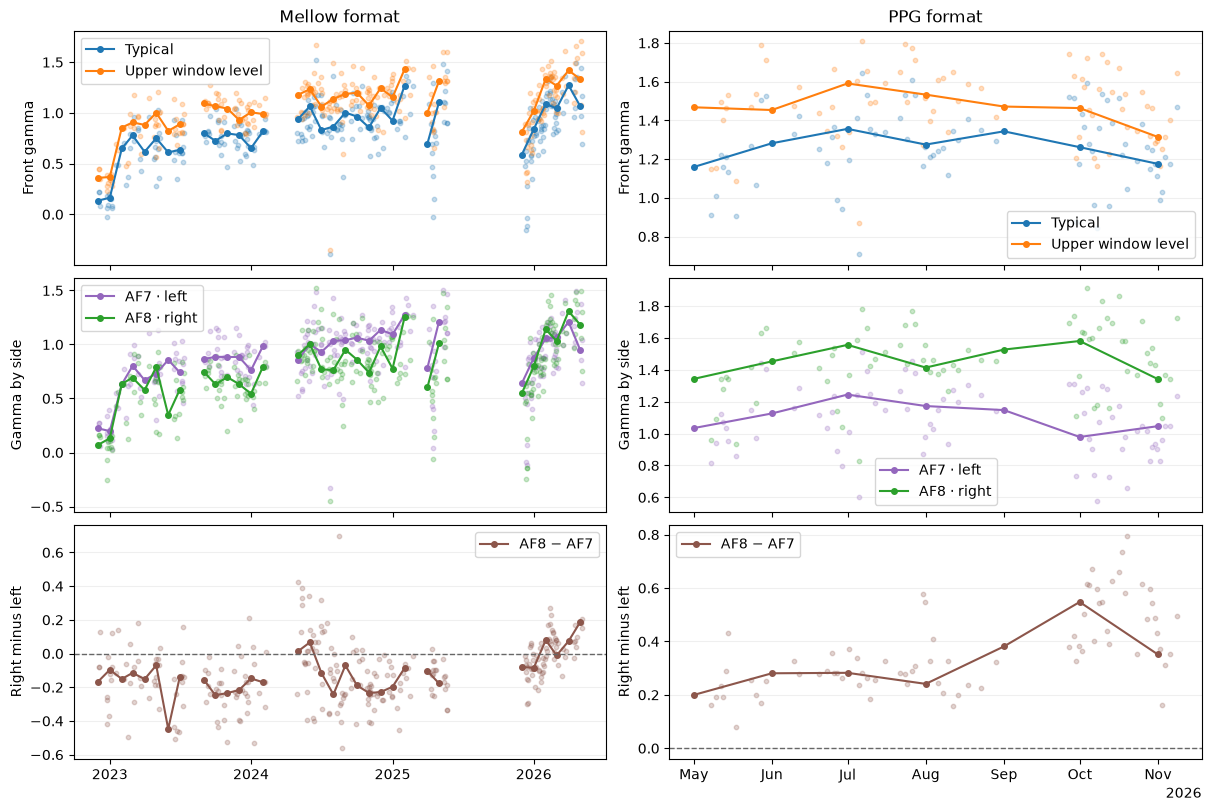

In [4]:
def plot_trend(ax, group, column, label, color):
    series = group.set_index("Started")[column]
    ax.scatter(series.index, series, color=color, s=10, alpha=0.25)
    monthly = series.resample("MS").agg(["median", "count"])
    enough = monthly["count"] >= MIN_SESSIONS_PER_MONTH
    ax.plot(monthly.index, monthly["median"].where(enough), "o-", color=color,
            markersize=4, label=label)


def format_date_axis(ax):
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


fig, axes = plt.subplots(3, len(formats), figsize=(6 * len(formats), 8),
                         sharex="col", squeeze=False, layout="constrained")
for column, recording_format in enumerate(formats):
    group = sessions.loc[sessions["Format"].eq(recording_format)]
    level, sides, shift = axes[:, column]
    level.set_title(recording_format)
    plot_trend(level, group, "Gamma_Front", "Typical", "tab:blue")
    plot_trend(level, group, "Gamma_upper", "Upper window level", "tab:orange")
    plot_trend(sides, group, "Gamma_AF7", "AF7 · left", "tab:purple")
    plot_trend(sides, group, "Gamma_AF8", "AF8 · right", "tab:green")
    plot_trend(shift, group, "Gamma_right_minus_left", "AF8 − AF7", "tab:brown")
    shift.axhline(0, color="0.4", linewidth=1, linestyle="--")
    format_date_axis(shift)
    for ax, label in zip((level, sides, shift), ("Front gamma", "Gamma by side", "Right minus left")):
        ax.set_ylabel(label)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="best")
plt.show()

## Other EEG bands

Each panel shows session medians for the sensor pair selected in Settings. The bands have their own vertical scales, so compare the direction and size of change within each panel.

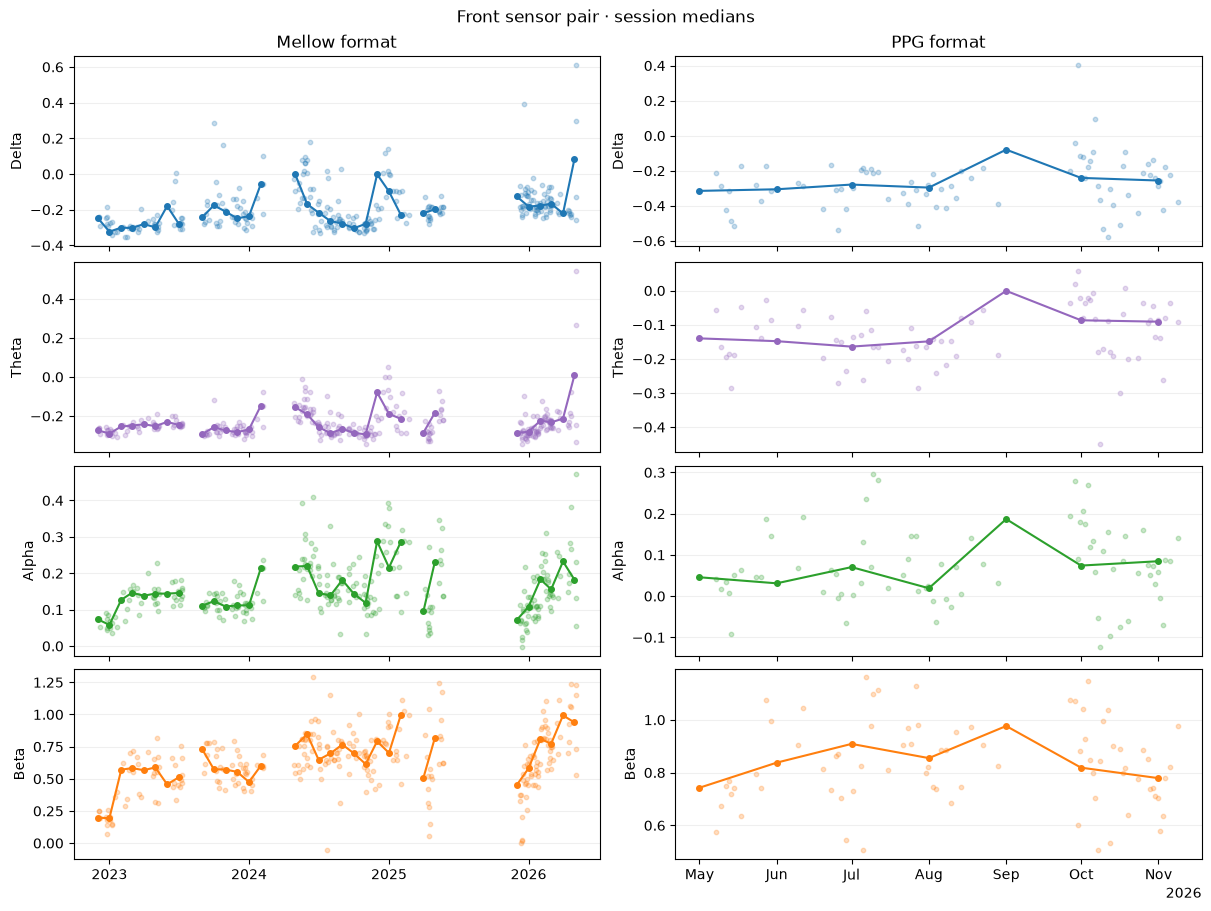

In [5]:
fig, axes = plt.subplots(4, len(formats), figsize=(6 * len(formats), 9),
                         sharex="col", squeeze=False, layout="constrained")
for column, recording_format in enumerate(formats):
    group = sessions.loc[sessions["Format"].eq(recording_format)]
    axes[0, column].set_title(recording_format)
    for ax, band, color in zip(axes[:, column], BANDS[:-1],
                               ("tab:blue", "tab:purple", "tab:green", "tab:orange")):
        plot_trend(ax, group, f"{band}_{SENSOR_PAIR}", f"{SENSOR_PAIR.lower()} pair", color)
        ax.set_ylabel(band)
        ax.grid(axis="y", alpha=0.2)
    format_date_axis(axes[-1, column])
fig.suptitle(f"{SENSOR_PAIR} sensor pair · session medians")
plt.show()

## Early versus late sessions

Compare the median of the first quarter of sessions with the last quarter within each format. These are descriptive changes in recorded units. The date ranges show which periods each comparison covers.

In [6]:
metrics = {
    "Front gamma": "Gamma_Front",
    "Upper front gamma": "Gamma_upper",
    "Gamma AF7 (left)": "Gamma_AF7",
    "Gamma AF8 (right)": "Gamma_AF8",
    "Gamma right minus left": "Gamma_right_minus_left",
    **{f"{band} ({SENSOR_PAIR.lower()})": f"{band}_{SENSOR_PAIR}" for band in BANDS[:-1]},
}
for recording_format, group in sessions.groupby("Format", sort=False):
    count = len(group) // 4
    if count < 3:
        continue
    early, late = group.head(count), group.tail(count)
    print(f"{recording_format} · {count} sessions per period")
    print(f"Early {early['Started'].min():%Y-%m-%d} to {early['Started'].max():%Y-%m-%d}")
    print(f"Late  {late['Started'].min():%Y-%m-%d} to {late['Started'].max():%Y-%m-%d}")
    comparison = pd.DataFrame({
        "Early": {label: early[column].median() for label, column in metrics.items()},
        "Late": {label: late[column].median() for label, column in metrics.items()},
    })
    comparison["Change"] = comparison["Late"] - comparison["Early"]
    display(comparison.round(3))

if "Gamma_lower_motion" in sessions:
    with_motion = sessions.dropna(subset=["Gamma_lower_motion"]).copy()
    with_motion["Gamma_change_when_quieter"] = with_motion["Gamma_lower_motion"] - with_motion["Gamma_Front"]
    with_motion["Side_change_when_quieter"] = with_motion["Side_lower_motion"] - with_motion["Gamma_right_minus_left"]
    print("Motion check · median change after omitting the highest-motion windows")
    display(with_motion.groupby("Format", sort=False).agg(
        Sessions=("File", "size"),
        Front_gamma=("Gamma_change_when_quieter", "median"),
        Right_minus_left=("Side_change_when_quieter", "median"),
    ).round(3))

Mellow format · 70 sessions per period
Early 2022-12-04 to 2023-11-28
Late  2025-12-13 to 2026-05-04


,Early,Late,Change
Front gamma,0.667,0.956,0.288
Upper front gamma,0.880,1.146,0.265
Gamma AF7 (left),0.741,0.957,0.216
Gamma AF8 (right),0.568,0.935,0.367
Gamma right minus left,-0.166,0.005,0.171
Delta (front),-0.272,-0.177,0.095
Theta (front),-0.260,-0.258,0.002
Alpha (front),0.118,0.137,0.019
Beta (front),0.534,0.681,0.146


PPG format · 19 sessions per period
Early 2026-05-07 to 2026-06-28
Late  2026-10-11 to 2026-11-08


,Early,Late,Change
Front gamma,1.211,1.211,-0.000
Upper front gamma,1.467,1.403,-0.064
Gamma AF7 (left),1.070,0.979,-0.091
Gamma AF8 (right),1.344,1.443,0.099
Gamma right minus left,0.264,0.489,0.225
Delta (front),-0.309,-0.256,0.053
Theta (front),-0.146,-0.091,0.055
Alpha (front),0.046,0.066,0.020
Beta (front),0.748,0.779,0.031


Motion check · median change after omitting the highest-motion windows


,Sessions,Front_gamma,Right_minus_left
Format,,,
PPG format,73,0.006,0.0


## Look inside one recording

Set `INSPECT_RECORDING` in Settings to a filename from the archive. The default uses the most recent usable recording. Each point is one 30-second window.

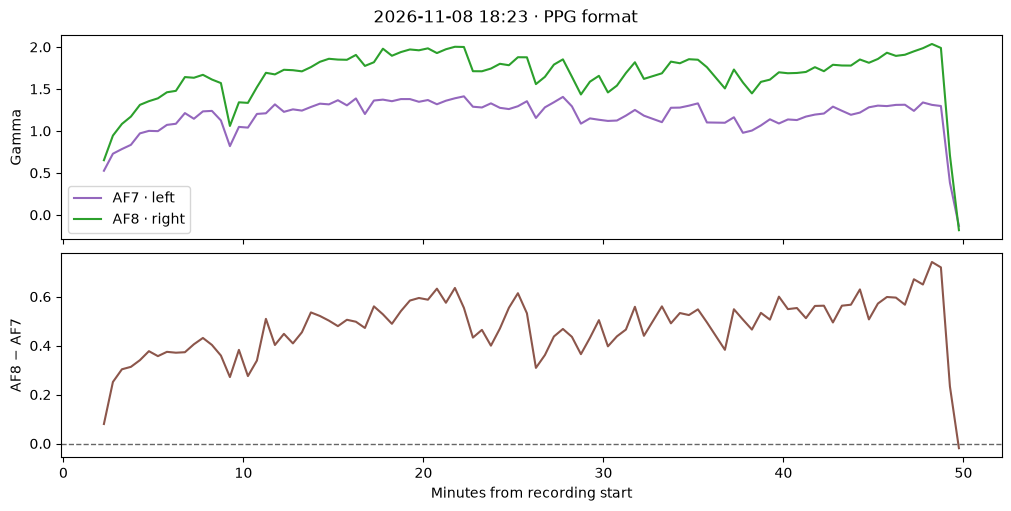

In [7]:
selected = INSPECT_RECORDING or sessions.iloc[-1]["File"]
summary, windows = summarize_recording(ARCHIVE / selected)
minutes = (windows.index + WINDOW_SECONDS / 2) / 60
fig, (gamma, side) = plt.subplots(2, 1, sharex=True, figsize=(10, 5), layout="constrained")
fig.suptitle(f"{summary['Started']:%Y-%m-%d %H:%M} · {summary['Format']}")
gamma.plot(minutes, windows["Gamma_AF7"], color="tab:purple", label="AF7 · left")
gamma.plot(minutes, windows["Gamma_AF8"], color="tab:green", label="AF8 · right")
gamma.set_ylabel("Gamma")
gamma.legend()
side.plot(minutes, windows["Gamma_right_minus_left"], color="tab:brown")
side.axhline(0, color="0.4", linewidth=1, linestyle="--")
side.set(xlabel="Minutes from recording start", ylabel="AF8 − AF7")
plt.show()